. Utilize the K-Means clustering algorithm to segment customers based on their 
purchasing behaviour. Apply the Elbow Method to determine the optimal number of 
clusters that best represent distinct customer segments for targeted marketing strategies. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("Wholesale customers data.csv")

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [4]:
df.isnull()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
435,False,False,False,False,False,False,False,False
436,False,False,False,False,False,False,False,False
437,False,False,False,False,False,False,False,False
438,False,False,False,False,False,False,False,False


In [5]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [6]:
x = df.drop(['Channel','Region'],axis=1)

x.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [7]:

q1 = x.quantile(0.25)
q3 = x.quantile(0.75)

iqr = q3 - q1

outliers = ((x < q1 - 1.5 * iqr) |
            (x > q3 + 1.5 * iqr)).any(axis=1)

x = x[~outliers]

    

print("Shape after IQR:", x.shape)

Shape after IQR: (332, 6)


In [8]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

print("Scaled Data Shape:", x_scaled.shape)

Scaled Data Shape: (332, 6)


Modification: Determine the optimal number of clusters (K) manually, using the Elbow Method, 
and using the Silhouette Method. Compare the results obtained from all three approaches and 
identify the most suitable value of K

In [9]:
# MANUAL METHOD
kmeans_manual = KMeans(n_clusters=3, random_state=42, n_init=10)

labels_manual = kmeans_manual.fit_predict(x_scaled)

print("Manual K:", 3)

Manual K: 3


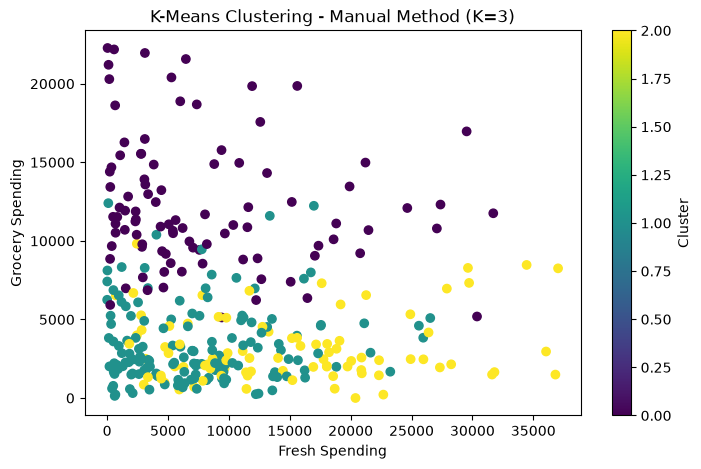

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x['Fresh'],
    x['Grocery'],
    c=labels_manual,
    cmap='viridis'
)

plt.title('K-Means Clustering - Manual Method (K=3)')
plt.xlabel('Fresh Spending')
plt.ylabel('Grocery Spending')
plt.colorbar(label='Cluster')
plt.show()

[1992.0, 1303.1342611098141, 1077.0435334708045, 920.5976378590718, 816.0674832515393, 743.7177311423043, 692.0083891378582, 655.2937920707661, 615.8084750882102, 585.816445934661]


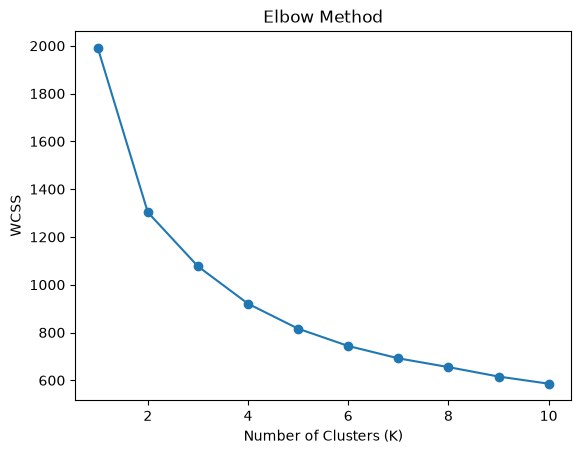

In [11]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(x_scaled)
    wcss.append(model.inertia_)
    
print(wcss)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

[0.3562115540974368, 0.25948485743221444, 0.271320099977572, 0.25628165794867774, 0.24124454195613565, 0.2376014271501244, 0.23667216373033648, 0.21580988186075833, 0.21749628972771395]


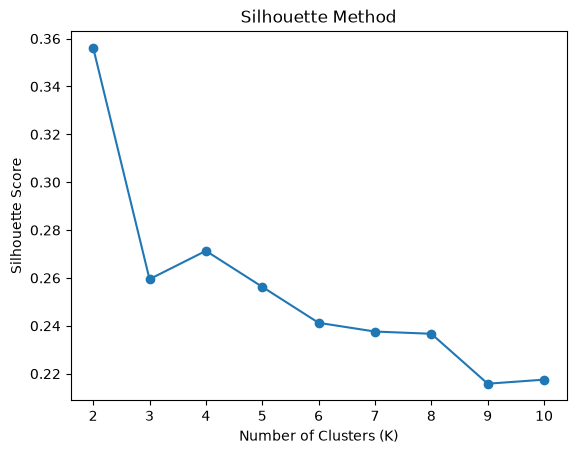

In [12]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)
    silhouette_scores.append(score)

print(silhouette_scores)

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method')
plt.show()

In [13]:
best_k = range(2, 11)[silhouette_scores.index(max(silhouette_scores))]

print("Best K using Silhouette Method:", best_k)
print("Highest Silhouette Score:", max(silhouette_scores))

Best K using Silhouette Method: 2
Highest Silhouette Score: 0.3562115540974368


In [14]:
manual_k = 3
elbow_k = 4  # Change this based on your Elbow graph
silhouette_k = best_k

comparison = pd.DataFrame({
    'Method': ['Manual Method', 'Elbow Method', 'Silhouette Method'],
    'Optimal K': [manual_k, elbow_k, silhouette_k]
})

print(comparison)

              Method  Optimal K
0      Manual Method          3
1       Elbow Method          4
2  Silhouette Method          2


In [15]:
print("Manual Method K:", manual_k)
print("Elbow Method K:", elbow_k)
print("Silhouette Method K:", silhouette_k)

print("Best K according to Silhouette Method:", silhouette_k)

Manual Method K: 3
Elbow Method K: 4
Silhouette Method K: 2
Best K according to Silhouette Method: 2


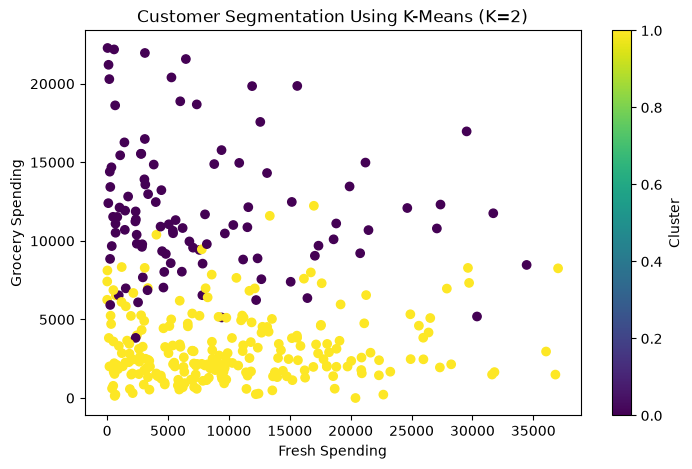

In [16]:
final_k = best_k  # Replace with your selected K

final_model = KMeans(n_clusters=final_k, random_state=42, n_init=10)
final_labels = final_model.fit_predict(x_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    x['Fresh'],
    x['Grocery'],
    c=final_labels,
    cmap='viridis'
)

plt.xlabel('Fresh Spending')
plt.ylabel('Grocery Spending')
plt.title(f'Customer Segmentation Using K-Means (K={final_k})')
plt.colorbar(label='Cluster')
plt.show()